# Week 3 – TF-IDF and Keyword Extraction
## Review-Informed Skincare Product Discovery Using NLP and Data Analytics

**Input:** `TheDermaCo_Sentiment_Analysis.csv`  
**Outputs:**
- `TheDermaCo_TFIDF_Top_Keywords.csv`
- `TheDermaCo_TFIDF_Review_Keywords.csv`

This notebook uses TF-IDF (Term Frequency–Inverse Document Frequency) to identify terms and phrases that are informative across the collected skincare reviews. It also compares important terms across predicted sentiment groups.

**Language note:** Reviews may contain English and Romanized Hinglish. We do not apply an English-only stop-word list, because it can remove useful words or sentiment cues. TF-IDF identifies statistically informative terms; it does not understand meaning by itself.

## Step 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.feature_extraction.text import TfidfVectorizer

print("Scikit-learn imported successfully!")
from IPython.display import display

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas:", pd.__version__)

Scikit-learn imported successfully!
Libraries imported successfully!
Pandas: 3.1.0


## Step 2 – Load the sentiment dataset

Keep `TheDermaCo_Sentiment_Analysis.csv` in the same folder as this notebook, or update the path.

In [2]:
input_file = "TheDermaCo_Sentiment_Analysis.csv"

df = pd.read_csv(input_file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset loaded successfully!
Shape: (162, 19)
Columns: ['review_id', 'product_name', 'reviewer_name', 'rating', 'review_title', 'review_text', 'review_date', 'verified_buyer', 'helpful_votes', 'not_helpful_votes', 'product_url', 'combined_review', 'cleaned_review', 'is_product_name_only', 'review_length', 'character_count', 'review_date_parsed', 'sentiment', 'sentiment_confidence']


,review_id,product_name,reviewer_name,rating,review_title,review_text,review_date,verified_buyer,helpful_votes,not_helpful_votes,product_url,combined_review,cleaned_review,is_product_name_only,review_length,character_count,review_date_parsed,sentiment,sentiment_confidence
0,e18ed183-d1fb-4f47-9e5c-84e2edb3010b,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Tejas,5,Good,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2026-09-13T05:10:00Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,Good 2% Sali-Cinamide Anti-Acne Face Wash with...,good 2 sali cinamide anti acne face wash with...,True,18,100,2026-09-13 05:10:00+00:00,Neutral,0.782745
1,8d555059-7343-4220-a9aa-98144cd5156e,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Kabibunisa,5,NaN,It is the super product for pimple remove,2026-08-14T02:29:15Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,It is the super product for pimple remove,it is the super product for pimple remove,False,8,41,2026-08-14 02:29:15+00:00,Positive,0.545851
2,a4d3af1b-81db-4efd-8667-1dc49e7deb3d,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Sayma,5,Fight acne and oil control,"Yeh derma ka best facewash h isme niacinamide,...",2026-08-07T05:40:16Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,Fight acne and oil control Yeh derma ka best f...,fight acne and oil control yeh derma ka best f...,False,80,418,2026-08-07 05:40:16+00:00,Positive,0.478471
3,1c619545-cd14-477e-9c28-5abe6fc21b9b,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Athar .,5,NaN,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2026-08-02T07:12:10Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2 sali cinamide anti acne face wash with 2 s...,True,17,95,2026-08-02 07:12:10+00:00,Neutral,0.830566
4,58d6f486-ec74-469e-b82b-ad8c4190fdfc,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Lucky,5,NaN,Nice,2026-02-22T05:52:29Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,Nice,nice,False,1,4,2026-02-22 05:52:29+00:00,Positive,0.473958


## Step 3 – Validate and prepare the review text

In [3]:
if "combined_review" not in df.columns:
    if {"review_title", "review_text"}.issubset(df.columns):
        df["review_title"] = df["review_title"].fillna("").astype(str)
        df["review_text"] = df["review_text"].fillna("").astype(str)
        df["combined_review"] = (
            df["review_title"] + " " + df["review_text"]
        ).str.strip()
    else:
        raise ValueError(
            "The dataset needs 'combined_review' or both "
            "'review_title' and 'review_text' columns."
        )

df["combined_review"] = df["combined_review"].fillna("").astype(str)

# Basic normalization: lowercase, remove URLs, retain letters/numbers and spaces.
# This intentionally keeps Romanized Hinglish words.
def prepare_tfidf_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["tfidf_text"] = df["combined_review"].apply(prepare_tfidf_text)

# Remove rows with no usable tokens after normalization.
df = df[df["tfidf_text"].str.len() > 0].copy()
df = df.reset_index(drop=True)

print("Reviews available for TF-IDF:", len(df))
display(df[["combined_review", "tfidf_text"]].head())

Reviews available for TF-IDF: 162


,combined_review,tfidf_text
0,Good 2% Sali-Cinamide Anti-Acne Face Wash with...,good 2 sali cinamide anti acne face wash with ...
1,It is the super product for pimple remove,it is the super product for pimple remove
2,Fight acne and oil control Yeh derma ka best f...,fight acne and oil control yeh derma ka best f...
3,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2 sali cinamide anti acne face wash with 2 sal...
4,Nice,nice


## Step 4 – Configure and fit the TF-IDF vectorizer

- `ngram_range=(1, 2)` extracts single words and two-word phrases.
- `min_df=2` ignores terms appearing in only one review.
- `max_features=5000` limits the vocabulary size.
- No English-only stop-word list is used, to avoid removing useful Hinglish words and negation terms.

In [4]:
vectorizer = TfidfVectorizer(
    lowercase=False,       # Text is already lowercased.
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000,
    sublinear_tf=True,
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix = vectorizer.fit_transform(df["tfidf_text"])
feature_names = vectorizer.get_feature_names_out()

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of extracted terms/phrases:", len(feature_names))

TF-IDF matrix shape: (162, 1015)
Number of extracted terms/phrases: 1015


## Step 5 – Extract top keywords across all reviews

The mean TF-IDF score ranks terms by their average importance across the review collection. It is not the same as simple word frequency.

In [5]:
mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).ravel()

top_keywords = pd.DataFrame({
    "Keyword_or_Phrase": feature_names,
    "Mean_TFIDF": mean_tfidf
}).sort_values(
    "Mean_TFIDF",
    ascending=False
).reset_index(drop=True)

top_20_keywords = top_keywords.head(20)

display(top_20_keywords)

,Keyword_or_Phrase,Mean_TFIDF
0,and,0.052980
1,the,0.052400
2,acne,0.050377
3,my,0.049186
4,i,0.046369
5,it,0.044318
6,this,0.044266
7,skin,0.043642
8,face,0.043561
9,wash,0.041002


## Step 6 – Visualize the top 20 keywords

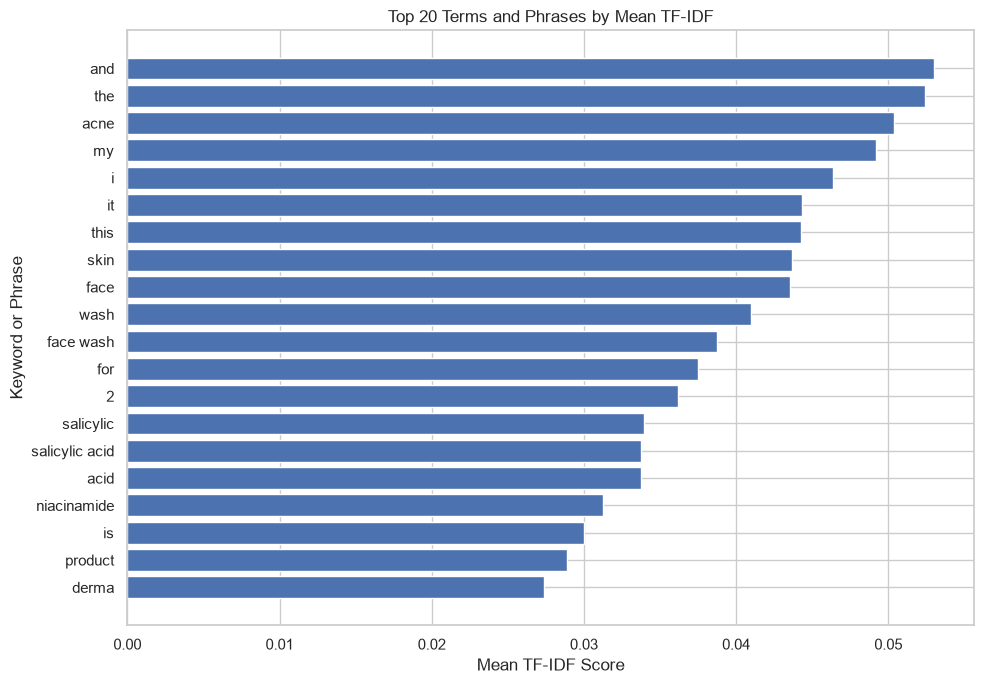

In [6]:
plot_data = top_20_keywords.sort_values("Mean_TFIDF", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(
    plot_data["Keyword_or_Phrase"],
    plot_data["Mean_TFIDF"]
)
plt.title("Top 20 Terms and Phrases by Mean TF-IDF")
plt.xlabel("Mean TF-IDF Score")
plt.ylabel("Keyword or Phrase")
plt.tight_layout()
plt.show()

## Step 7 – Extract keywords by predicted sentiment

This section uses the `sentiment` column created in the previous notebook. The results describe terms that are informative within each predicted sentiment group; they are not proof that a term caused that sentiment.

In [7]:
if "sentiment" not in df.columns:
    print("No 'sentiment' column found. Skipping sentiment-group keyword extraction.")
else:
    sentiment_keyword_tables = []

    for sentiment in ["Positive", "Neutral", "Negative"]:
        group_indices = df.index[df["sentiment"].astype(str).str.capitalize() == sentiment].tolist()

        if len(group_indices) < 2:
            print(f"Skipping {sentiment}: fewer than 2 reviews.")
            continue

        group_matrix = vectorizer.transform(df.loc[group_indices, "tfidf_text"])
        group_mean = np.asarray(group_matrix.mean(axis=0)).ravel()

        group_top = pd.DataFrame({
            "Sentiment": sentiment,
            "Keyword_or_Phrase": feature_names,
            "Mean_TFIDF": group_mean
        }).sort_values(
            "Mean_TFIDF",
            ascending=False
        ).head(20)

        sentiment_keyword_tables.append(group_top)

    if sentiment_keyword_tables:
        sentiment_keywords = pd.concat(
            sentiment_keyword_tables,
            ignore_index=True
        )
        display(sentiment_keywords)
    else:
        sentiment_keywords = pd.DataFrame(
            columns=["Sentiment", "Keyword_or_Phrase", "Mean_TFIDF"]
        )

,Sentiment,Keyword_or_Phrase,Mean_TFIDF
0,Positive,and,0.052832
1,Positive,the,0.052441
2,Positive,acne,0.050022
3,Positive,my,0.049560
4,Positive,it,0.048459
5,Positive,skin,0.048031
6,Positive,this,0.047591
7,Positive,i,0.046491
8,Positive,face,0.041968
9,Positive,wash,0.039863


## Step 8 – Visualize top keywords for each sentiment

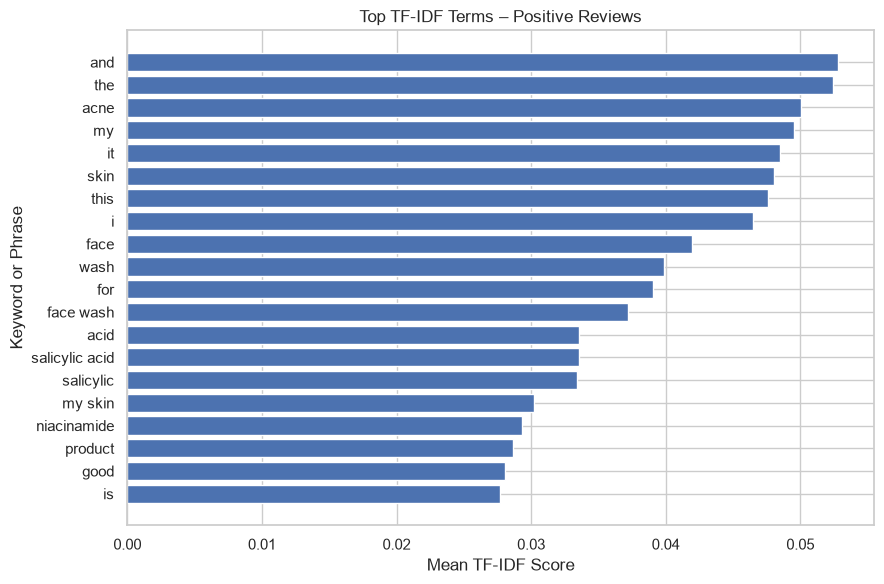

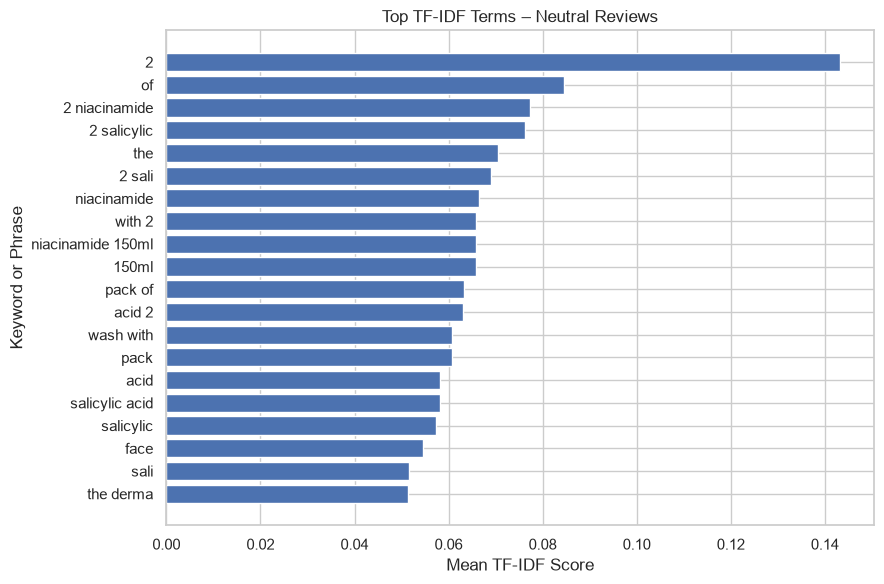

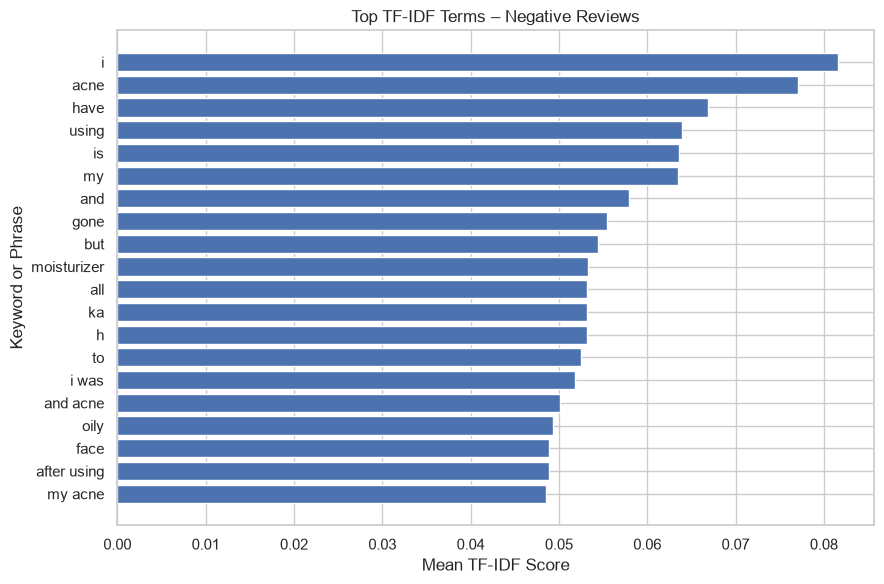

In [9]:
if "sentiment" in df.columns and not sentiment_keywords.empty:
    for sentiment in ["Positive", "Neutral", "Negative"]:
        group_plot = sentiment_keywords[
            sentiment_keywords["Sentiment"] == sentiment
        ].sort_values("Mean_TFIDF", ascending=True)

        if group_plot.empty:
            continue

        plt.figure(figsize=(9, 6))
        plt.barh(
            group_plot["Keyword_or_Phrase"],
            group_plot["Mean_TFIDF"]
        )
        plt.title(f"Top TF-IDF Terms – {sentiment} Reviews")
        plt.xlabel("Mean TF-IDF Score")
        plt.ylabel("Keyword or Phrase")
        plt.tight_layout()
        plt.show()
else:
    print("Sentiment-group keyword charts are not available.")

## Step 9 – Find the highest-scoring terms for each review

For each review, this identifies up to three terms/phrases with the highest TF-IDF values. These are useful for inspecting individual reviews, but should not be treated as automatically extracted topics.

In [8]:
review_keywords = []

for row_number in range(tfidf_matrix.shape[0]):
    row = tfidf_matrix.getrow(row_number)

    if row.nnz == 0:
        keywords = []
    else:
        ranked_positions = np.argsort(row.data)[::-1][:3]
        keywords = [
            feature_names[row.indices[position]]
            for position in ranked_positions
        ]

    review_keywords.append(", ".join(keywords))

df["top_tfidf_keywords"] = review_keywords

columns_to_show = [
    col for col in [
        "rating",
        "sentiment",
        "combined_review",
        "top_tfidf_keywords"
    ] if col in df.columns
]

display(df[columns_to_show].head(15))

,rating,sentiment,combined_review,top_tfidf_keywords
0,5,Neutral,Good 2% Sali-Cinamide Anti-Acne Face Wash with...,"2, 150ml pack, pack of"
1,5,Positive,It is the super product for pimple remove,"product for, super, remove"
2,5,Positive,Fight acne and oil control Yeh derma ka best f...,"h, ka, facewash"
3,5,Neutral,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,"2, 150ml pack, niacinamide 150ml"
4,5,Positive,Nice,nice
5,5,Neutral,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,"2, with 2, niacinamide 150ml"
6,5,Positive,This product is super awesome. I started using...,"started, i am, am"
7,5,Negative,Absolutely w... Absolutely worth it product\nI...,"will, and acne, you will"
8,5,Positive,This anti ac... This anti acne face wash is go...,"this anti, good, have"
9,5,Positive,This product... This product is great for sens...,"this facewash, this product, great for"


## Step 10 – Export TF-IDF results

In [10]:
top_keywords.to_csv(
    "TheDermaCo_TFIDF_Top_Keywords.csv",
    index=False,
    encoding="utf-8-sig"
)

df.to_csv(
    "TheDermaCo_TFIDF_Review_Keywords.csv",
    index=False,
    encoding="utf-8-sig"
)

if "sentiment" in df.columns and not sentiment_keywords.empty:
    sentiment_keywords.to_csv(
        "TheDermaCo_TFIDF_Sentiment_Keywords.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("TF-IDF outputs exported successfully!")
print("1. TheDermaCo_TFIDF_Top_Keywords.csv")
print("2. TheDermaCo_TFIDF_Review_Keywords.csv")
if "sentiment" in df.columns and not sentiment_keywords.empty:
    print("3. TheDermaCo_TFIDF_Sentiment_Keywords.csv")

TF-IDF outputs exported successfully!
1. TheDermaCo_TFIDF_Top_Keywords.csv
2. TheDermaCo_TFIDF_Review_Keywords.csv
3. TheDermaCo_TFIDF_Sentiment_Keywords.csv


## Step 11 – Final summary

In [11]:
print("=" * 58)
print("THE DERMA CO – TF-IDF AND KEYWORD EXTRACTION SUMMARY")
print("=" * 58)
print("Reviews analyzed:", len(df))
print("Vocabulary size:", len(feature_names))
print("N-gram range: unigrams and bigrams")
print("Minimum document frequency: 2")
print("\nTop 10 terms/phrases:")
display(top_keywords.head(10))
print("=" * 58)

THE DERMA CO – TF-IDF AND KEYWORD EXTRACTION SUMMARY
Reviews analyzed: 162
Vocabulary size: 1015
N-gram range: unigrams and bigrams
Minimum document frequency: 2

Top 10 terms/phrases:


,Keyword_or_Phrase,Mean_TFIDF
0,and,0.052980
1,the,0.052400
2,acne,0.050377
3,my,0.049186
4,i,0.046369
5,it,0.044318
6,this,0.044266
7,skin,0.043642
8,face,0.043561
9,wash,0.041002


## Interpretation and limitations

- TF-IDF gives higher weight to terms that are useful for distinguishing documents in this dataset.
- Mean TF-IDF is a ranking measure, not a measure of customer satisfaction.
- Common words may still appear because no generic English stop-word list was applied; review the top terms and create a domain-specific stop-word list only when justified.
- English and Romanized Hinglish may be tokenized as separate vocabulary items; spelling variations can split similar words.
- With 162 reviews, treat findings as exploratory and avoid broad claims about all skincare customers.
- Review the top terms in context before turning them into customer feedback themes.